# US Treasury Yield Curve: PCA Analysis

This notebook asks "What drives the US Treasury yield curve?". It downloads daily Treasury yields from FRED for 11 maturities from 1 month to 30 years (2010 - 2026), calculates daily changes in yields, in basis points, not yield levels, and runs principal component analysis (PCA). The 1M maturity is then dropped, because it behaved differently from the rest of the curve.

Main finding: after dropping the 1M, the first component explains 80.1% of the daily movement, up from 74.4%, and three components are enough to explain over 95% (95.7%).

## 1. Load the data
Download daily US Treasury yields from FRED for 11 maturities (1 month to 30 years), from January 2010 onward. Days with any missing maturity, such as holidays, are dropped.

In [12]:
import pandas as pd

# The tenors (maturities) we want, and their FRED series codes
series = {
    "1M": "DGS1MO", "3M": "DGS3MO", "6M": "DGS6MO", "1Y": "DGS1",
    "2Y": "DGS2", "3Y": "DGS3", "5Y": "DGS5", "7Y": "DGS7",
    "10Y": "DGS10", "20Y": "DGS20", "30Y": "DGS30",
}

# Download each series from FRED, starting from 2010
columns = {}
for tenor, code in series.items():
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={code}&cosd=2010-01-01"
    columns[tenor] = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0]

# Combine into one table and drop days where any tenor is missing (e.g. holidays)
yields = pd.DataFrame(columns).dropna()

print(yields.shape)   # (number of days, number of tenors)
yields.head()         # show the first 5 rows

(4200, 11)


,1M,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y
observation_date,,,,,,,,,,,
2010-01-04,0.05,0.08,0.18,0.45,1.09,1.66,2.65,3.36,3.85,4.60,4.65
2010-01-05,0.03,0.07,0.17,0.41,1.01,1.57,2.56,3.28,3.77,4.54,4.59
2010-01-06,0.03,0.06,0.15,0.40,1.01,1.60,2.60,3.33,3.85,4.63,4.70
2010-01-07,0.02,0.05,0.16,0.40,1.03,1.62,2.62,3.33,3.85,4.62,4.69
2010-01-08,0.02,0.05,0.15,0.37,0.96,1.56,2.57,3.31,3.83,4.61,4.70


## 2. What the curve looks like on different dates
Upward-sloping in 2010 and 2021, inverted in 2023 (short yields above long yields), and humped in 2026. The 10Y was about the same in 2010 and mid-2023, but the curves were very different, so one tenor can't describe the whole curve.

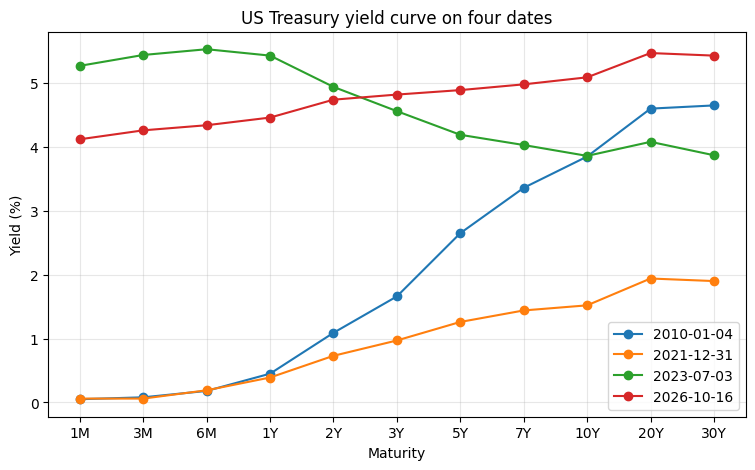

In [13]:
import matplotlib.pyplot as plt

# Four dates to compare: after the 2008 crisis, before the 2022 hikes,
# mid-2023, and the latest date in your data
dates = ["2010-01-04", "2021-12-31", "2023-07-03", yields.index[-1]]

plt.figure(figsize=(9, 5))
for d in dates:
    day = yields.index.asof(pd.Timestamp(d))   # nearest available trading day
    plt.plot(yields.columns, yields.loc[day], marker="o", label=str(day.date()))

plt.xlabel("Maturity")
plt.ylabel("Yield (%)")
plt.title("US Treasury yield curve on four dates")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Level and slope on the same four dates. 2010 has the steepest slope (+460 bp), 2023 is the only inverted curve (−140 bp), and 2026 has a level similar to 2023 but a positive slope.

In [14]:
rows = []
for d in ["2010-01-04", "2021-12-31", "2023-07-03", yields.index[-1]]:
    day = yields.index.asof(pd.Timestamp(d))
    y = yields.loc[day]
    rows.append({
        "date": day.date(),
        "level: average yield (%)": round(y.mean(), 2),
        "slope: 30Y minus 1M (bp)": round((y["30Y"] - y["1M"]) * 100),
        "slope: 10Y minus 2Y (bp)": round((y["10Y"] - y["2Y"]) * 100),
    })

pd.DataFrame(rows)

,date,level: average yield (%),slope: 30Y minus 1M (bp),slope: 10Y minus 2Y (bp)
0,2010-01-04,2.06,460,276
1,2021-12-31,0.95,184,79
2,2023-07-03,4.65,-140,-108
3,2026-10-16,4.78,131,35


## 3. Daily changes
Convert yields into daily changes in basis points. The PCA uses changes rather than yield levels, because levels trend over time and would hide how the curve actually moves day to day.

In [15]:
import pandas as pd

# 1. Re-download the yields from FRED (so this cell works on its own)
series = {
    "1M": "DGS1MO", "3M": "DGS3MO", "6M": "DGS6MO", "1Y": "DGS1",
    "2Y": "DGS2", "3Y": "DGS3", "5Y": "DGS5", "7Y": "DGS7",
    "10Y": "DGS10", "20Y": "DGS20", "30Y": "DGS30",
}
columns = {}
for tenor, code in series.items():
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={code}&cosd=2010-01-01"
    columns[tenor] = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
yields = pd.DataFrame(columns).dropna()

# 2. Daily changes in basis points
changes = yields.diff().dropna() * 100

print(changes.shape)
print("Volatility (standard deviation of daily change, in bp):")
print(changes.std().round(1))

(4199, 11)
Volatility (standard deviation of daily change, in bp):
1M     4.0
3M     2.5
6M     2.5
1Y     3.4
2Y     4.6
3Y     4.9
5Y     5.4
7Y     5.5
10Y    5.3
20Y    5.3
30Y    5.2
dtype: float64


## 4. How the maturities move together
Correlation of daily changes. Neighbouring maturities move together (7Y and 10Y: 0.97), distant ones less so (2Y and 30Y: 0.54), and the 1M is almost unrelated to the long end (1M and 30Y: 0.04). The strong correlations are why a few factors can describe the curve.

       1M    3M    6M    1Y    2Y    3Y    5Y    7Y   10Y   20Y   30Y
1M   1.00  0.18  0.13  0.09  0.06  0.05  0.04  0.04  0.04  0.04  0.04
3M   0.18  1.00  0.65  0.44  0.33  0.30  0.25  0.22  0.21  0.18  0.16
6M   0.13  0.65  1.00  0.74  0.60  0.54  0.46  0.41  0.37  0.30  0.27
1Y   0.09  0.44  0.74  1.00  0.82  0.75  0.65  0.58  0.52  0.41  0.37
2Y   0.06  0.33  0.60  0.82  1.00  0.93  0.86  0.79  0.72  0.59  0.54
3Y   0.05  0.30  0.54  0.75  0.93  1.00  0.94  0.89  0.82  0.70  0.65
5Y   0.04  0.25  0.46  0.65  0.86  0.94  1.00  0.97  0.93  0.83  0.78
7Y   0.04  0.22  0.41  0.58  0.79  0.89  0.97  1.00  0.97  0.90  0.86
10Y  0.04  0.21  0.37  0.52  0.72  0.82  0.93  0.97  1.00  0.96  0.93
20Y  0.04  0.18  0.30  0.41  0.59  0.70  0.83  0.90  0.96  1.00  0.98
30Y  0.04  0.16  0.27  0.37  0.54  0.65  0.78  0.86  0.93  0.98  1.00


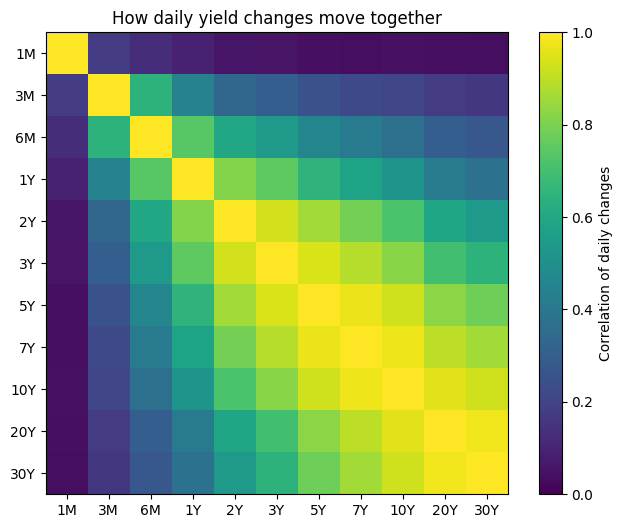

In [16]:
import matplotlib.pyplot as plt

corr = changes.corr()
print(corr.round(2))

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="Correlation of daily changes")
plt.xticks(range(len(corr)), corr.columns)
plt.yticks(range(len(corr)), corr.columns)
plt.title("How daily yield changes move together")
plt.show()

## 5. PCA: how many factors?
Eigendecomposition of the covariance matrix of daily changes. With all 11 maturities, PC1 explains 74.4% and it takes four components to pass 95%.

In [17]:
import numpy as np

# Covariance of daily changes (bp), then its eigenvalues
cov = np.cov(changes.values, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov)

# Sort from largest to smallest
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

# Share of total variation explained by each component
explained = eigvals / eigvals.sum()

result = pd.DataFrame({
    "explained (%)": (explained * 100).round(1),
    "cumulative (%)": (explained.cumsum() * 100).round(1),
}, index=[f"PC{i+1}" for i in range(len(explained))])
print(result)

      explained (%)  cumulative (%)
PC1            74.4            74.4
PC2            10.9            85.3
PC3             7.2            92.6
PC4             3.5            96.1
PC5             1.5            97.6
PC6             0.8            98.4
PC7             0.6            99.0
PC8             0.4            99.5
PC9             0.2            99.7
PC10            0.2            99.9
PC11            0.1           100.0


## 6. Loadings: what the factors look like
PC1 has all-positive loadings (level: the whole curve moves together). PC2 flips sign between the 5Y and 7Y (slope: short and long ends move in opposite directions). PC3 was almost entirely the 1M (loading about 0.97), so one whole component was used up by a single maturity.

      PC1   PC2   PC3
1M   0.02 -0.15  0.97
3M   0.05 -0.20  0.13
6M   0.09 -0.28  0.05
1Y   0.17 -0.42 -0.03
2Y   0.29 -0.44 -0.11
3Y   0.35 -0.33 -0.10
5Y   0.40 -0.11 -0.07
7Y   0.42  0.06 -0.03
10Y  0.40  0.20  0.03
20Y  0.37  0.38  0.09
30Y  0.35  0.43  0.11


<Axes: title={'center': 'Loadings by maturity'}>

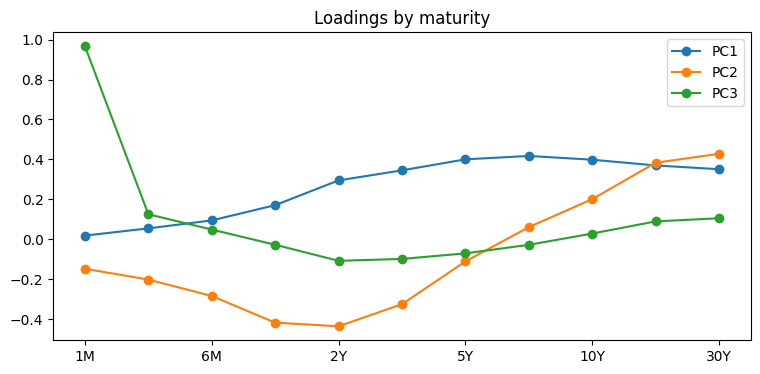

In [18]:
loadings = pd.DataFrame(
    eigvecs[:, :3],
    index=changes.columns,
    columns=["PC1", "PC2", "PC3"],
)

# Sign convention: flip each component so the 30Y loading is positive
for pc in loadings.columns:
    if loadings.loc["30Y", pc] < 0:
        loadings[pc] = -loadings[pc]

print(loadings.round(2))
loadings.plot(marker="o", figsize=(9, 4), title="Loadings by maturity")

## 7. Dropping the 1M
The 1M had higher volatility than the 3M and 6M, almost no correlation with the long end, and took over PC3 on its own. Without it, PC1 rises to 80.1% and three components explain 95.7%. PC3 now shows ends against middle. The trade-off is that the analysis covers 3M to 30Y only.

Variance explained, PC1-PC4 (%):
[80.1 11.7  3.9  1.6]
      PC1   PC2   PC3
3M   0.05 -0.19  0.64
6M   0.09 -0.28  0.49
1Y   0.17 -0.42  0.25
2Y   0.29 -0.44 -0.15
3Y   0.35 -0.33 -0.25
5Y   0.40 -0.12 -0.25
7Y   0.42  0.06 -0.15
10Y  0.40  0.20 -0.00
20Y  0.37  0.39  0.20
30Y  0.35  0.44  0.27
Cumulative (%): [80.1 91.8 95.7 97.4]


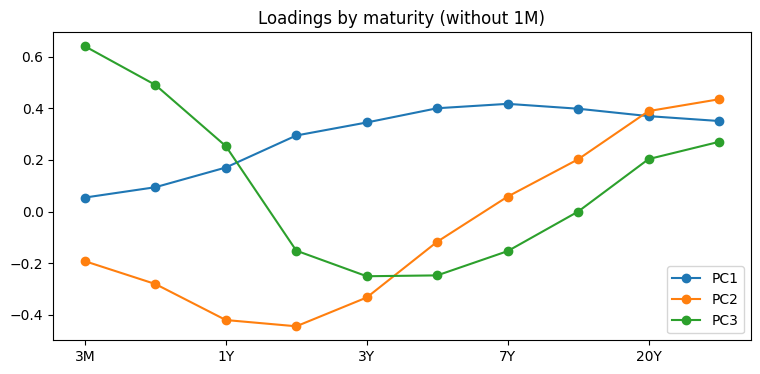

In [19]:
changes_no1m = changes.drop(columns="1M")
cov2 = np.cov(changes_no1m.values, rowvar=False)
vals, vecs = np.linalg.eigh(cov2)
order = np.argsort(vals)[::-1]
vals, vecs = vals[order], vecs[:, order]

print("Variance explained, PC1-PC4 (%):")
print((vals[:4] / vals.sum() * 100).round(1))

load2 = pd.DataFrame(vecs[:, :3], index=changes_no1m.columns, columns=["PC1", "PC2", "PC3"])
for pc in load2.columns:
    if load2.loc["30Y", pc] < 0:
        load2[pc] = -load2[pc]
print(load2.round(2))
load2.plot(marker="o", figsize=(9, 4), title="Loadings by maturity (without 1M)");
share = vals / vals.sum() * 100
print("Cumulative (%):", share.cumsum().round(1)[:4])

## 8. Which tenors each factor explains
For each maturity, the share of its own daily movement that comes from level, slope and curvature. Level dominates 3Y to 20Y (above 80%). Slope matters most at 1Y and 6M. Curvature only matters at 3M and 6M, and is under 5% for every tenor from 1Y to 30Y.

In [20]:
import numpy as np
import pandas as pd

# Download yields from FRED
series = {
    "1M": "DGS1MO", "3M": "DGS3MO", "6M": "DGS6MO", "1Y": "DGS1",
    "2Y": "DGS2", "3Y": "DGS3", "5Y": "DGS5", "7Y": "DGS7",
    "10Y": "DGS10", "20Y": "DGS20", "30Y": "DGS30",
}
columns = {}
for tenor, code in series.items():
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={code}&cosd=2010-01-01"
    columns[tenor] = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
yields = pd.DataFrame(columns).dropna()

# Daily changes in basis points
changes = yields.diff().dropna() * 100

# PCA without the 1M
data = changes.drop(columns="1M")
cov = np.cov(data.values, rowvar=False)
vals, vecs = np.linalg.eigh(cov)
order = np.argsort(vals)[::-1]
vals, vecs = vals[order], vecs[:, order]

# How much of each tenor's movement comes from each of the top 3 factors
k = 3
contrib = pd.DataFrame(
    vecs[:, :k] ** 2 * vals[:k] / np.diag(cov)[:, None],
    index=data.columns,
    columns=["PC1 level", "PC2 slope", "PC3 curvature"],
)
out = (contrib * 100).round(1)
out["top 3 total"] = out.sum(axis=1).round(1)
out["daily vol (bp)"] = data.std().round(1)

print(changes.shape)
print(out)

(4199, 11)
     PC1 level  PC2 slope  PC3 curvature  top 3 total  daily vol (bp)
3M         7.8       14.3           53.3         75.4             2.5
6M        23.2       30.0           30.8         84.0             2.5
1Y        42.6       37.8            4.6         85.0             3.4
2Y        70.3       23.3            0.9         94.5             4.6
3Y        83.6       11.4            2.2         97.2             4.9
5Y        94.6        1.2            1.8         97.6             5.4
7Y        96.9        0.3            0.6         97.8             5.5
10Y       94.9        3.6            0.0         98.5             5.3
20Y       83.8       13.6            1.2         98.6             5.3
30Y       77.9       17.5            2.3         97.7             5.2


## Conclusions and limitations
Three factors (level, slope and a short-end curvature factor) explain over 95% of daily curve movement, with level alone explaining 80.1%. PC3 has a curvature-shaped sign pattern, but in this data it mainly describes the 3M and 6M.

Limitations: one pooled sample period (2010 onward) with no regime analysis, in-sample results only, and the analysis covers 3M to 30Y after dropping the 1M. Why the 1M behaves differently is untested.

Next steps: rolling-window PCA, a PCA-based hedging experiment, and an out-of-sample test.